
# Workshop -1 Adding Sunglasses to Your Passport Photo Using OpenCV
# Name : BUSHPIKA C
# Reg No : 212225230038

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

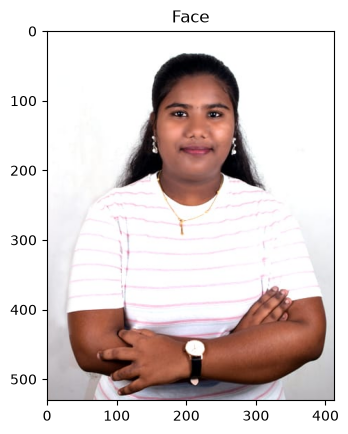

In [2]:
# Load the Face Image
faceImage = cv2.imread('bushpassport.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [3]:
faceImage.shape

(531, 413, 3)

In [4]:
#resized_faceImage.shape
faceImage.shape

(531, 413, 3)

Text(0.5, 1.0, 'glassPNG')

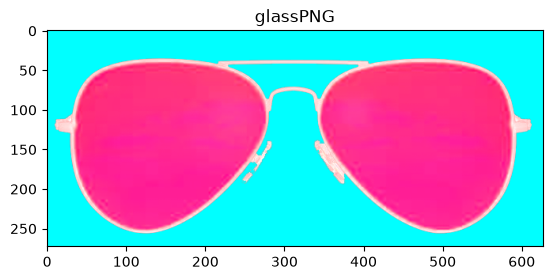

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('Sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [6]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(250, 80))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(80, 250, 4)


In [7]:
# Separate color and alpha channels
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]

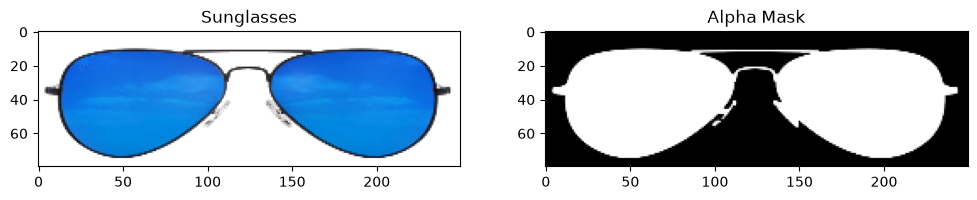

In [8]:
# Display sunglasses and alpha mask
plt.figure(figsize=(12,5))

plt.subplot(121)
plt.imshow(glassBGR[:,:,::-1])
plt.title("Sunglasses")

plt.subplot(122)
plt.imshow(glassMask1, cmap="gray")
plt.title("Alpha Mask")

plt.show()

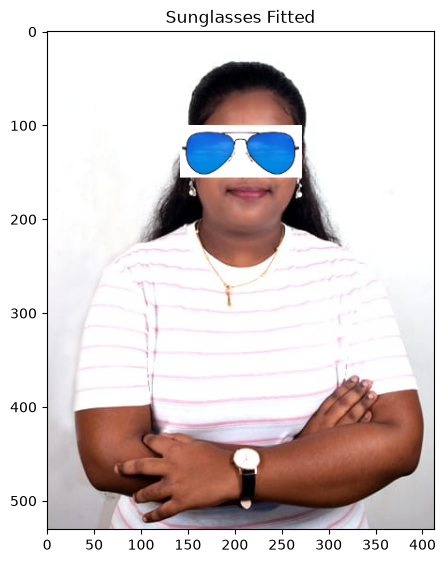

In [9]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses
glassResized = cv2.resize(glassBGR, (130, 56))

# Place sunglasses over eyes
x = 142
y = 100

h, w = glassResized.shape[:2]

# Apply sunglasses
faceWithGlassesNaive[y:y+h, x:x+w] = glassResized

# Display
plt.figure(figsize=(5,7))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses Fitted")
plt.axis("on")
plt.show()

Eye ROI: (63, 145, 3)
Glass Mask: (63, 145, 3)
Sunglasses: (63, 145, 3)


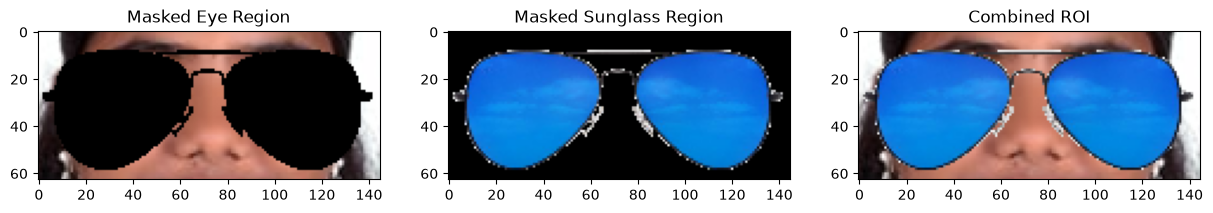

In [10]:

# ==========================================
# STEP 1: LOAD AND RESIZE SUNGLASSES
# ==========================================

# Load original sunglasses image
glassBGR = cv2.imread("Sunglass.png")

if glassBGR is None:
    raise ValueError("Sunglasses image not found!")

# Resize sunglasses
glassBGR = cv2.resize(glassBGR, (145, 63))

# ==========================================
# STEP 2: CREATE MASK
# ==========================================

# Convert sunglasses to grayscale
glassMask1 = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

# Remove white background
_, glassMask1 = cv2.threshold(
    glassMask1, 245, 255, cv2.THRESH_BINARY_INV
)

# Create 3-channel mask
glassMask = cv2.merge((
    glassMask1,
    glassMask1,
    glassMask1
))

# Convert mask values to 0 and 1
glassMask = np.uint8(glassMask / 255)

# ==========================================
# STEP 3: MAKE A COPY OF FACE IMAGE
# ==========================================

faceWithGlasses = faceImage.copy()

# ==========================================
# STEP 4: EYE REGION COORDINATES
# ==========================================

x = 142
y = 100

h, w = glassBGR.shape[:2]

# Extract eye ROI
eyeROI = faceWithGlasses[y:y+h, x:x+w]

# Check dimensions
print("Eye ROI:", eyeROI.shape)
print("Glass Mask:", glassMask.shape)
print("Sunglasses:", glassBGR.shape)

# ==========================================
# STEP 5: MASKING OPERATION
# ==========================================

# Remove region where sunglasses will be placed
maskedEye = cv2.multiply(eyeROI, 1 - glassMask)

# Extract sunglasses using mask
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace eye region with combined image
faceWithGlasses[y:y+h, x:x+w] = eyeRoiFinal

# ==========================================
# STEP 6: DISPLAY INTERMEDIATE RESULTS
# ==========================================

plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye, cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass, cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(cv2.cvtColor(eyeRoiFinal, cv2.COLOR_BGR2RGB))
plt.title("Combined ROI")

plt.show()

# ==========================================
# STEP 7: DISPLAY FINAL OUTPUT
# ==========================================



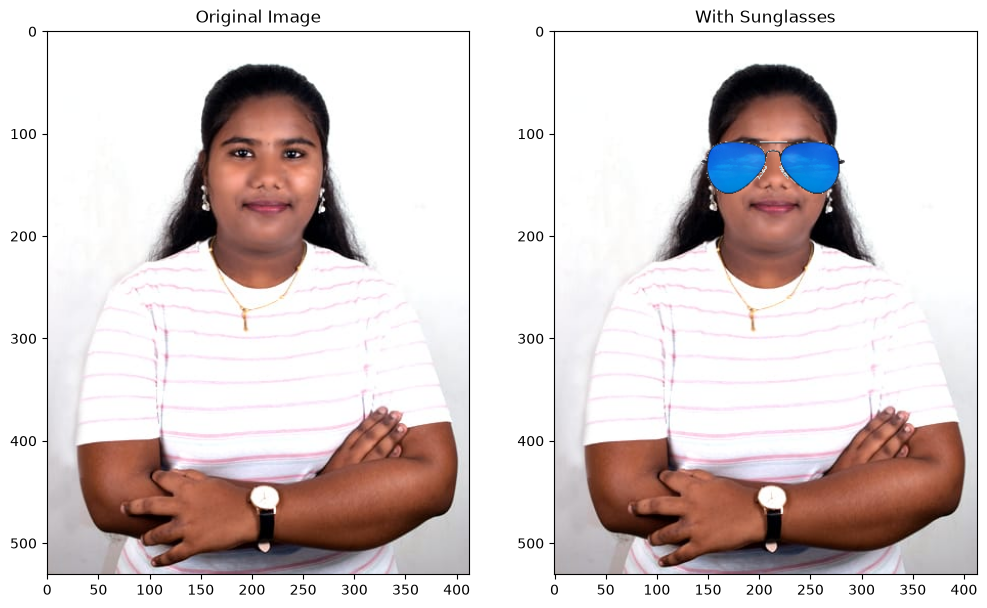

In [11]:
# Final Result
plt.figure(figsize=(12,8))

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")
plt.axis("on")

plt.subplot(122)
plt.imshow(faceWithGlasses[:,:,::-1])
plt.title("With Sunglasses")
plt.axis("on")

plt.show()